# Roteiro 9 - Redes Neurais I

Este é o roteiro da décima aula de laboratório da disciplina de Inteligência Artificial ministrada em 2024-2025 na UFMT.

O objetivo é desenvolver um classificador utilizando uma rede neural de três camadas para a base de dados de dígitos manuscritos MNIST (Modified National Institute of Standards and Technology).

Como não haverá treinamento da Rede Neural nesta aula, você deve testar sua implementação utilizando os parâmetros $W^{[2]}, b^{[2]}, W{[3]}$ e $b{[3]}$ gravados no arquivo `pesos.mat` (carregue-o com o comando load). A acurácia (precisão) do reconhecimento com estes parâmetros deve ser igual a $97.5%$.

O documento está organizado da seguinte forma:


1.   Implementação da função sigmoid
2.   Implementação do Modelo de previsão com 3 camadas (**Exercício 1.0 ponto**)
3.   Avaliação e Cálculo da acurácia



---


Autor: raoni.teixeira@ufmt.br

# 1.  Carregando pacotes

In [ ]:
import numpy as np
from scipy.io import loadmat
import matplotlib.pyplot as plt

# 2. Baixando dados
Baixar as imagens de  e os pesos de um rede já *treinada*

In [ ]:
!gdown 1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz
!gdown 1fe_0HxYCYF0R94GZytN0mgK_mWDnDond

Downloading...
From (original): https://drive.google.com/uc?id=1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz
From (redirected): https://drive.google.com/uc?id=1zyLpE4VpOd32vVkVBzH_Xy1V4u7rXMJz&confirm=t&uuid=b185ebc5-7243-4c0c-93df-0f9f124b4c52
To: /content/mnistdata.mat
100% 7.51M/7.51M [00:00<00:00, 178MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1fe_0HxYCYF0R94GZytN0mgK_mWDnDond
From (redirected): https://drive.google.com/uc?id=1fe_0HxYCYF0R94GZytN0mgK_mWDnDond&confirm=t&uuid=d08ab00b-a586-423f-b5f3-fca51d3fb729
To: /content/pesos.mat
100% 82.6k/82.6k [00:00<00:00, 53.5MB/s]


# 3. Sobre os dados




O conjunto de dados utilizado nesta atividade é uma pequena parte da base
[MNIST](https://pt.wikipedia.org/wiki/Banco_de_dados_MNIST) de dı́gitos manuscritos (arquivo `mnistdata.mat.`).

A amostra considerada contém 5000 imagens de tamanho $20 \times 20$, normalizadas no intervalo $[0-1]$.


Cada imagem dessa base de dados é uma matriz $20 \times 20 \in \mathbf{R}²$ .  A matriz armazena a intensidade do pixel em tons de cinza. Os valores $0$ e $1$ correspondem as cores preta e branca, respectivamente. Quanto mais perto de $0$ mais escuro é o pixel. Veja a Figura abaixo.



In [ ]:
def load_data():
    data = loadmat("mnistdata.mat")
    X = data["X"]
    y = data["y"].flatten()
    return X, y

def load_weights():
    weights = loadmat("pesos.mat")
    W2 = weights["W2"]
    b2 = weights["b2"]
    W3 = weights["W3"]
    b3 = weights["b3"]

    return W2, b2, W3, b3

print("Carregando dados...")
X, y = load_data()

Carregando dados...


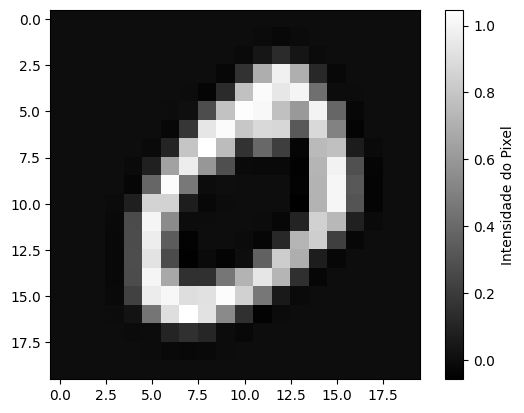

In [ ]:
imagem = X[0,:].reshape(20,20).T
plt.imshow(imagem, cmap='gray')
plt.colorbar(label="Intensidade do Pixel")
plt.show()

As imagens estão armazendas em uma matriz `X` com tamanho $5000 \times 400$ (cada linha de X é uma imagem). A classe de cada imagem está armazenda em um vetor `y` de tamanho $5000 \times 1$). Os valores
de y variam de $1$ à $10$. O dı́gito $0$ (zero) é representado pelo número $10$ e os outros dı́gitos são representados de maneira natural (i.e., os dı́gitos de $1$ à $9$ são representados utilizando os números de $1$ à $9$).

In [ ]:
def display_random_images(X, y):
    indices = np.random.choice(X.shape[0], 100, replace=False)
    images = X[indices, :].reshape(-1, 20, 20).transpose(0, 2, 1)
    labels = y[indices]

    fig, axes = plt.subplots(10, 10, figsize=(8, 8))
    for i, ax in enumerate(axes.flat):
        ax.imshow(images[i], cmap='gray')
        ax.set_title(f"{labels[i]}", fontsize=8)
        ax.axis('off')
    plt.tight_layout()
    plt.show()

# 4. Visualizando uma amostra de imagens

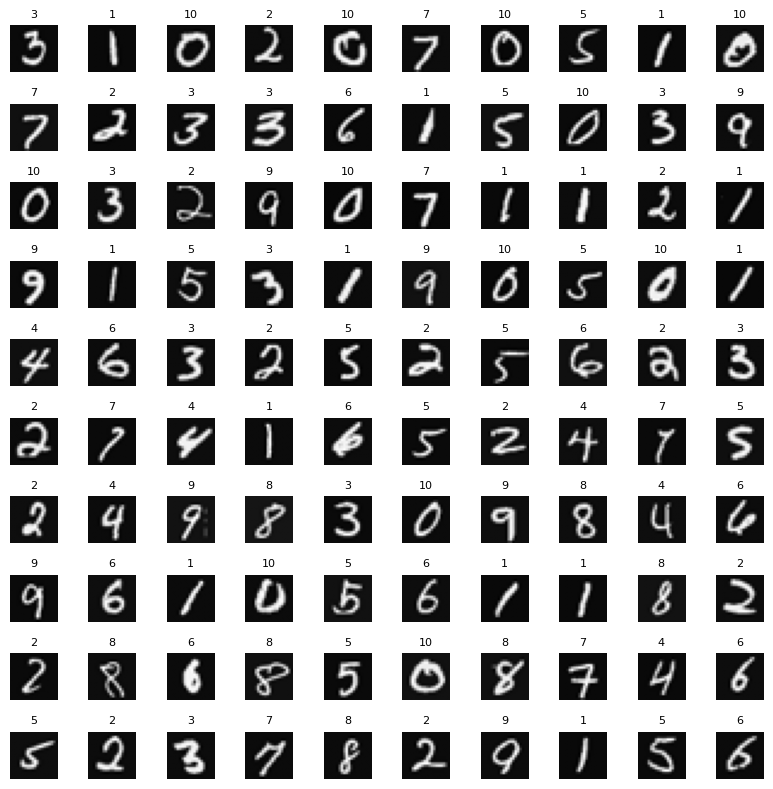

Carregando pesos treinados...


In [ ]:
display_random_images(X, y)

print("Carregando pesos treinados...")
W2, b2, W3, b3 = load_weights()



# 5. Modelo


A Figura abaixo mostra a arquitetura da rede neural considerada nesta atividade. Esta rede possui três camadas: entrada, intermedária e saı́da.

Como estamos trabalhando com imagens de tamanho $20 \times 20$, precisamos de $400$ unidades na camada de entrada (uma unidade para cada pixel da imagem).
Há ainda $25$ unidades na camada intermediária e $10$ unidades de saı́da (uma
para cada dı́gito possı́vel). Nesta representação não incluı́mos a unidade +1
que corresponde ao viés (bias) do modelo.

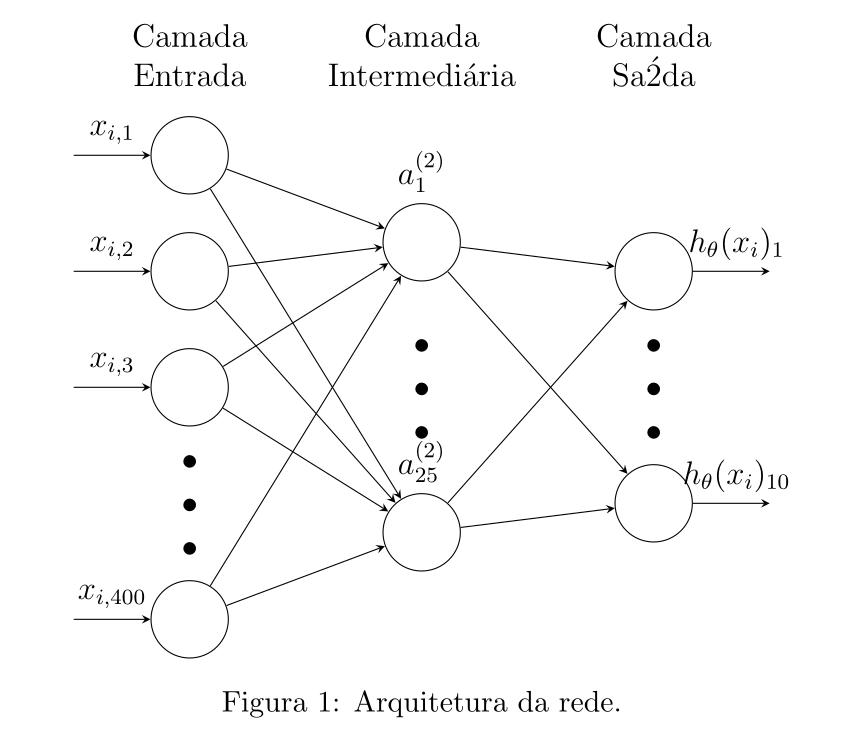

Observe que a camada de do modelo saída possui um neurônio para cada possível classe --  10 classes e 10 neurônios na camada final. Cada um desses neurônios gera um valor entre 0 e 1, graças à função de ativação sigmoide, que comprime qualquer entrada numérica para esse intervalo.

Esses valores representam a confiança da rede em cada uma das 10 classes. No entanto, como a ativação sigmoide não garante que a soma das saídas seja 1, cada neurônio funciona de forma independente, sem uma interpretação direta como probabilidade. Assim, a decisão final do classificador é simples: escolhemos o neurônio com o maior valor, pois ele representa a classe que a rede considera mais provável.

Essa abordagem funciona bem na prática porque, durante o treinamento, os pesos da rede são ajustados para que a ativação do neurônio correto seja a mais alta possível. Portanto, ao alimentar a rede com uma nova entrada, basta identificar o índice do neurônio com maior ativação para determinar a classe prevista.

# 6. Exercício (1.0 ponto)

Implemente a propagação *feedfoward* para classificar as imagens em  $X$. Para tanto, você deve completar a função
 `predict` que deve devolver, para cada imagem, um número inteiro entre 1 e 10 indicando a qual classe a imagem pertence.

Sua função deve primeiro calcular:

1. $a^{(1)} = x_i$
2. $z^{(2)} = W^{[2]} a^{(1)} + b^{[2]}$
3. $a^{(2)} = g(z^{ (2)} ) $
4. $z^{ (3)} = W^{[3]} a^{(2)} + b^{[3]}$
5. $a^{(3)} = g(z^{ (3)} ) $

E, em seguida, devolver, para cada imagem, o neurônio da $a^{(3)}$ com maior probabilidade (dica: use `np.argmax`).

In [ ]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def predict(W2, b2, W3, b3, X):
    m = X.shape[0]


    return np.argmax(a3, axis=1) + 1


Se sua implementação estiver correta a acurácia (porcentagem de acertos) deve ser igual à 97.52%.

In [ ]:
print("Fazendo previsões...")
pred = predict(W2, b2, W3, b3, X)
acc = np.mean(pred == y) * 100
print(f"Acurácia da rede: {acc:.2f}%")

Fazendo previsões...
Acurácia da rede: 97.52%
